# Transformer Transfer Learning with PyTorch
## AG News → IMDB: Full Fine-Tuning vs. Classifier-Only Fine-Tuning

This notebook implements **both approaches in one workflow**:

1. Train a Transformer encoder classifier on **AG News** (4 news categories).
2. Reuse its learned encoder weights for **IMDB** sentiment classification (2 classes).
3. Compare:
   - **Full fine-tuning:** update the Transformer encoder and the new classifier.
   - **Classifier-only fine-tuning:** freeze the Transformer encoder and train only the new classifier.

> **Important clarification:** AG News training here is supervised source-task training, not language-model pre-training. It teaches the encoder useful representations for news classification, which we then transfer to sentiment classification.

### Practical choices
- Uses a small, readable Transformer encoder built with `torch.nn`.
- Uses a shared vocabulary learned from AG News; IMDB words not in that vocabulary become `<unk>`.
- Uses trainable embedding vectors rather than GloVe, so the notebook downloads fewer assets and runs with fewer compatibility issues.
- Uses Hugging Face `datasets` only to download the public datasets.
- Defaults to manageable subsets for a CPU laptop. Increase the limits for a more thorough experiment.

**Labels**
- AG News: `0=World`, `1=Sports`, `2=Business`, `3=Sci/Tech`
- IMDB: `0=Negative`, `1=Positive`


## 0. Install dependencies
Run this cell once in your notebook environment.

In [23]:
%pip install -q --upgrade torch datasets huggingface_hub scikit-learn matplotlib tqdm

## 1. Imports and reproducibility

In [24]:
import re
import copy
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.15.0+cu132


## 2. Experiment settings

The defaults below are deliberately modest for a CPU-only laptop. Start with these settings to verify that everything works. You can increase the sample limits and epochs later.

- `AG_TRAIN_LIMIT`: number of AG News training rows used.
- `IMDB_TRAIN_LIMIT`: number of IMDB training rows used.
- `MAX_LEN`: maximum tokens per review/article.
- `BATCH_SIZE`: number of examples per batch.


In [25]:
# Dataset sizes: use None to use the full split (takes much longer).
AG_TRAIN_LIMIT = 20000
AG_TEST_LIMIT = 4000
IMDB_TRAIN_LIMIT = 10000
IMDB_TEST_LIMIT = 5000

MAX_VOCAB_SIZE = 30000
MAX_LEN = 128
BATCH_SIZE = 32
EMBED_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 2
FF_DIM = 256
DROPOUT = 0.2

AG_EPOCHS = 6
IMDB_EPOCHS = 3
LEARNING_RATE = 2e-4
FINE_TUNE_LR = 1e-4
HEAD_LR = 5e-4

PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
PAD_ID = 0
UNK_ID = 1

print("Settings loaded.")

Settings loaded.


## 3. Download AG News and IMDB

In [26]:
!pip install -U datasets huggingface_hub

In [27]:
from datasets import load_dataset

# AG News dataset
ag_dataset = load_dataset("fancyzhx/ag_news")

# IMDB dataset
imdb_dataset = load_dataset("stanfordnlp/imdb")

print(ag_dataset)
print(imdb_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [28]:
def take_rows(split, limit=None):
    rows = list(split)
    if limit is not None:
        rows = rows[:limit]
    return rows

ag_train_rows = take_rows(ag_dataset["train"], AG_TRAIN_LIMIT)
ag_test_rows = take_rows(ag_dataset["test"], AG_TEST_LIMIT)

imdb_train_rows = take_rows(imdb_dataset["train"], IMDB_TRAIN_LIMIT)
imdb_test_rows = take_rows(imdb_dataset["test"], IMDB_TEST_LIMIT)

print("AG train/test:", len(ag_train_rows), len(ag_test_rows))
print("IMDB train/test:", len(imdb_train_rows), len(imdb_test_rows))
print("\nAG example:", ag_train_rows[0])
print("\nIMDB example:", imdb_train_rows[0]["text"][:300], "...")


AG train/test: 20000 4000
IMDB train/test: 10000 5000

AG example: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}

IMDB example: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...


## 4. Tokenization and vocabulary

A tokenizer splits text into tokens. The vocabulary maps each known token to an integer ID.

Example:

`"I love this movie"` → `["i", "love", "this", "movie"]` → `[12, 98, 34, 721]`

We build the vocabulary **only from AG News training text**. This keeps the transfer experiment clean: the IMDB dataset does not add new vocabulary entries.


In [29]:
def tokenize(text):
    # Simple lowercase word/punctuation tokenizer for teaching purposes.
    return re.findall(r"[a-z0-9]+|[^\w\s]", text.lower())

counter = Counter()
for row in tqdm(ag_train_rows, desc="Building AG News vocabulary"):
    counter.update(tokenize(row["text"]))

most_common = counter.most_common(MAX_VOCAB_SIZE - 2)
vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
for token, _ in most_common:
    if token not in vocab:
        vocab[token] = len(vocab)

VOCAB_SIZE = len(vocab)
print("Vocabulary size:", VOCAB_SIZE)
print("Sample token IDs:", {w: vocab.get(w, UNK_ID) for w in ["world", "sports", "love", "movie"]})

Building AG News vocabulary:   0%|          | 0/20000 [00:00<?, ?it/s]

Vocabulary size: 30000
Sample token IDs: {'world': 66, 'sports': 407, 'love': 3378, 'movie': 1825}


## 5. Numerical encoding and PyTorch Dataset

In [30]:
def encode_text(text):
    token_ids = [vocab.get(tok, UNK_ID) for tok in tokenize(text)]
    token_ids = token_ids[:MAX_LEN]
    if not token_ids:
        token_ids = [UNK_ID]
    return token_ids

class TextClassificationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return encode_text(row["text"]), int(row["label"])

def collate_batch(batch):
    # Pad each sequence in this batch to the longest sequence in the batch.
    sequences, labels = zip(*batch)
    max_batch_len = max(len(seq) for seq in sequences)

    padded = torch.full((len(sequences), max_batch_len), PAD_ID, dtype=torch.long)
    for i, seq in enumerate(sequences):
        padded[i, :len(seq)] = torch.tensor(seq, dtype=torch.long)

    labels = torch.tensor(labels, dtype=torch.long)
    return padded, labels

ag_train_loader = DataLoader(
    TextClassificationDataset(ag_train_rows),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
ag_test_loader = DataLoader(
    TextClassificationDataset(ag_test_rows),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)

imdb_train_loader = DataLoader(
    TextClassificationDataset(imdb_train_rows),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
imdb_test_loader = DataLoader(
    TextClassificationDataset(imdb_test_rows),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)

sample_x, sample_y = next(iter(ag_train_loader))
print("Input batch shape:", sample_x.shape)
print("Label batch shape:", sample_y.shape)
print("First encoded example:", sample_x[0][:20].tolist())


Input batch shape: torch.Size([32, 82])
Label batch shape: torch.Size([32])
First encoded example: [736, 120, 3771, 9, 3, 287, 2591, 15, 37, 16, 37, 5, 533, 7, 1133, 5846, 8, 2635, 1172, 11]


## 6. Positional embeddings and Transformer classifier

The model has five main parts:

1. **Token embedding:** converts token IDs into vectors.
2. **Position embedding:** adds word-order information.
3. **Transformer encoder:** uses self-attention to contextualize each token.
4. **Masked mean pooling:** averages only real tokens, not padding tokens.
5. **Linear classifier:** maps the pooled representation to class scores (logits).

The same encoder architecture is used for AG News and IMDB. Only the final classifier size changes from 4 outputs to 2.


In [31]:
class TransformerTextClassifier(nn.Module):
    def __init__(
        self, vocab_size, num_classes, max_len=128,
        embed_dim=128, num_heads=4, num_layers=2,
        ff_dim=256, dropout=0.2, pad_id=0
    ):
        super().__init__()
        self.pad_id = pad_id
        self.token_embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_len, embed_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, input_ids):
        batch_size, seq_len = input_ids.shape
        positions = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)

        # True means "ignore this position" for PyTorch's key-padding mask.
        padding_mask = input_ids.eq(self.pad_id)
        encoded = self.encoder(x, src_key_padding_mask=padding_mask)

        # Masked average pooling: padding positions do not contribute.
        valid_mask = (~padding_mask).unsqueeze(-1).float()
        summed = (encoded * valid_mask).sum(dim=1)
        counts = valid_mask.sum(dim=1).clamp(min=1.0)
        pooled = summed / counts

        logits = self.classifier(self.dropout(pooled))
        return logits

ag_model = TransformerTextClassifier(
    vocab_size=VOCAB_SIZE,
    num_classes=4,
    max_len=MAX_LEN,
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    pad_id=PAD_ID
).to(DEVICE)

print(ag_model)
print("Trainable parameters:", sum(p.numel() for p in ag_model.parameters() if p.requires_grad))

TransformerTextClassifier(
  (token_embedding): Embedding(30000, 128, padding_idx=0)
  (position_embedding): Embedding(128, 128)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=4, bias=True)
)
Trainable parameters: 4121860


## 7. Training and evaluation functions

In [32]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_predictions, all_labels = [], []
    criterion = nn.CrossEntropyLoss()

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for input_ids, labels in tqdm(loader, leave=False):
            input_ids = input_ids.to(DEVICE)
            labels = labels.to(DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(input_ids)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.extend(predictions.detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_predictions)
    return average_loss, accuracy


def fit_model(model, train_loader, valid_loader, epochs, learning_rate, optimizer_parameters=None):
    if optimizer_parameters is None:
        optimizer_parameters = [p for p in model.parameters() if p.requires_grad]

    optimizer = torch.optim.AdamW(optimizer_parameters, lr=learning_rate)
    history = {"train_loss": [], "train_acc": [], "valid_loss": [], "valid_acc": []}
    best_acc = -1.0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        valid_loss, valid_acc = run_epoch(model, valid_loader)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["valid_loss"].append(valid_loss)
        history["valid_acc"].append(valid_acc)

        if valid_acc > best_acc:
            best_acc = valid_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
            f"valid loss {valid_loss:.4f}, acc {valid_acc:.4f} | "
            f"{time.time() - start:.1f}s"
        )

    model.load_state_dict(best_state)
    return history

## 8. Train the source model on AG News

The source model learns to classify four kinds of news. After training, we save its parameters. The learned token embeddings and Transformer encoder are what we want to transfer to IMDB.


In [33]:
ag_history = fit_model(
    ag_model,
    ag_train_loader,
    ag_test_loader,
    epochs=AG_EPOCHS,
    learning_rate=LEARNING_RATE
)

torch.save(
    {
        "model_state_dict": ag_model.state_dict(),
        "vocab": vocab,
        "config": {
            "vocab_size": VOCAB_SIZE,
            "max_len": MAX_LEN,
            "embed_dim": EMBED_DIM,
            "num_heads": NUM_HEADS,
            "num_layers": NUM_LAYERS,
            "ff_dim": FF_DIM,
            "dropout": DROPOUT
        }
    },
    "ag_news_transformer.pt"
)
print("Saved: ag_news_transformer.pt")

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1/6 | train loss 0.9901, acc 0.5873 | valid loss 0.8182, acc 0.6853 | 9.9s


  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2/6 | train loss 0.6461, acc 0.7569 | valid loss 0.6905, acc 0.7508 | 12.2s


... (8 outputs left out)

Epoch 5/6 | train loss 0.3447, acc 0.8798 | valid loss 0.6079, acc 0.8127 | 7.7s


  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

Epoch 6/6 | train loss 0.2878, acc 0.9013 | valid loss 0.6448, acc 0.8070 | 7.7s
Saved: ag_news_transformer.pt


### Plot AG News learning curves

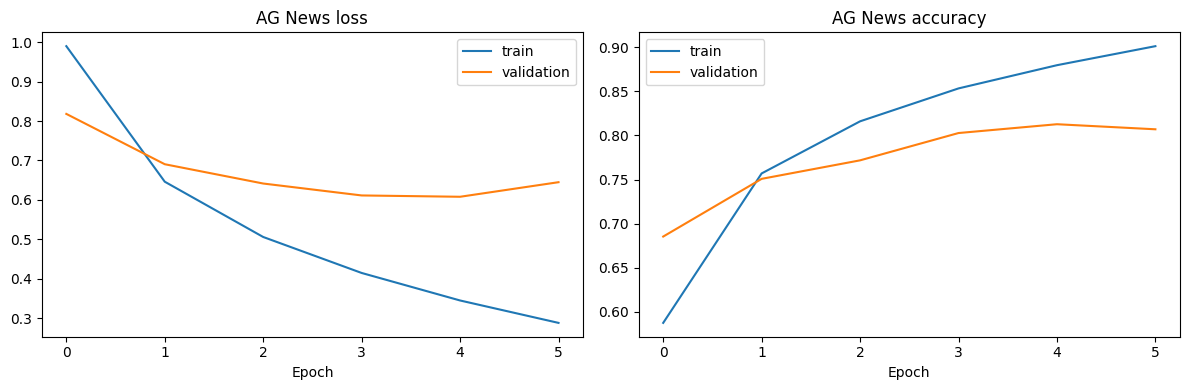

In [34]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ag_history["train_loss"], label="train")
plt.plot(ag_history["valid_loss"], label="validation")
plt.title("AG News loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ag_history["train_acc"], label="train")
plt.plot(ag_history["valid_acc"], label="validation")
plt.title("AG News accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Prepare the IMDB validation split

We split the available IMDB training rows into a training set and a validation set. The test set remains untouched until final evaluation.

The vocabulary is still the AG News vocabulary. Words that were not present in AG News map to `<unk>`.


In [35]:
imdb_train_part, imdb_valid_part = train_test_split(
    imdb_train_rows,
    test_size=0.15,
    random_state=SEED,
    stratify=[row["label"] for row in imdb_train_rows]
)

imdb_train_loader = DataLoader(
    TextClassificationDataset(imdb_train_part),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
imdb_valid_loader = DataLoader(
    TextClassificationDataset(imdb_valid_part),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)

print("IMDB train:", len(imdb_train_part))
print("IMDB validation:", len(imdb_valid_part))
print("IMDB test:", len(imdb_test_rows))

IMDB train: 8500
IMDB validation: 1500
IMDB test: 5000


## 10. Build the IMDB model and transfer AG News weights

The AG News classifier outputs 4 scores. IMDB needs 2 scores.

We therefore:
1. Create a new model with `num_classes=2`.
2. Copy the AG News token embeddings, position embeddings, and Transformer encoder.
3. Do **not** copy the old 4-class classifier. The new 2-class classifier starts with fresh weights.

This is the key transfer-learning step.


In [36]:
def make_imdb_model_from_ag(ag_model):
    imdb_model = TransformerTextClassifier(
        vocab_size=VOCAB_SIZE,
        num_classes=2,
        max_len=MAX_LEN,
        embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        ff_dim=FF_DIM,
        dropout=DROPOUT,
        pad_id=PAD_ID
    )

    # Copy the shared representation layers.
    imdb_model.token_embedding.load_state_dict(ag_model.token_embedding.state_dict())
    imdb_model.position_embedding.load_state_dict(ag_model.position_embedding.state_dict())
    imdb_model.encoder.load_state_dict(ag_model.encoder.state_dict())

    return imdb_model.to(DEVICE)

# Both experiments start from the exact same AG News encoder weights.
full_model = make_imdb_model_from_ag(ag_model)
head_only_model = make_imdb_model_from_ag(ag_model)

print("IMDB output classes:", full_model.classifier.out_features)

IMDB output classes: 2


## 11. Approach A — Full fine-tuning

All parameters are trainable:
- token embeddings
- position embeddings
- Transformer encoder
- new 2-class classifier

The whole network can adapt its representations to movie-review sentiment.


In [37]:
for parameter in full_model.parameters():
    parameter.requires_grad = True

full_trainable = sum(p.numel() for p in full_model.parameters() if p.requires_grad)
print("Trainable parameters (full fine-tuning):", f"{full_trainable:,}")

full_history = fit_model(
    full_model,
    imdb_train_loader,
    imdb_valid_loader,
    epochs=IMDB_EPOCHS,
    learning_rate=FINE_TUNE_LR
)

Trainable parameters (full fine-tuning): 4,121,602


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.0307, acc 0.9929 | valid loss 0.0003, acc 1.0000 | 4.4s


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 2/3 | train loss 0.0004, acc 1.0000 | valid loss 0.0001, acc 1.0000 | 4.5s


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 3/3 | train loss 0.0002, acc 1.0000 | valid loss 0.0001, acc 1.0000 | 4.9s


## 12. Approach B — Classifier-only fine-tuning

Freeze every parameter, then unfreeze only the new classifier.

`requires_grad = False` means PyTorch will not calculate parameter gradients for that parameter. The encoder still performs its forward computation, but its weights are not updated.


In [38]:
for parameter in head_only_model.parameters():
    parameter.requires_grad = False

for parameter in head_only_model.classifier.parameters():
    parameter.requires_grad = True

head_trainable = sum(p.numel() for p in head_only_model.parameters() if p.requires_grad)
print("Trainable parameters (classifier only):", f"{head_trainable:,}")
print("Percentage of full model trainable:", f"{100 * head_trainable / full_trainable:.2f}%")

head_history = fit_model(
    head_only_model,
    imdb_train_loader,
    imdb_valid_loader,
    epochs=IMDB_EPOCHS,
    learning_rate=HEAD_LR,
    optimizer_parameters=head_only_model.classifier.parameters()
)

Trainable parameters (classifier only): 258
Percentage of full model trainable: 0.01%


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.0954, acc 0.9918 | valid loss 0.0132, acc 1.0000 | 3.3s


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 2/3 | train loss 0.0119, acc 0.9991 | valid loss 0.0057, acc 1.0000 | 2.9s


  0%|          | 0/266 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 3/3 | train loss 0.0062, acc 0.9996 | valid loss 0.0033, acc 1.0000 | 3.0s


## 13. Compare validation learning curves

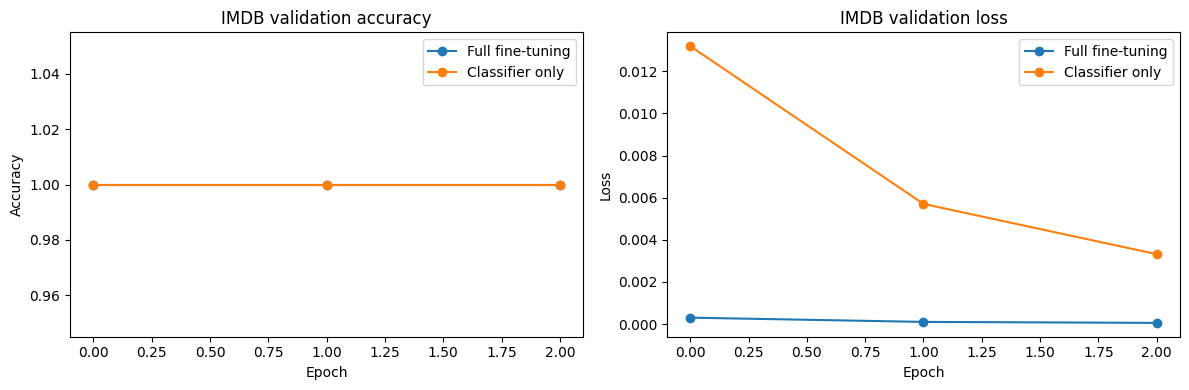

In [39]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(full_history["valid_acc"], marker="o", label="Full fine-tuning")
plt.plot(head_history["valid_acc"], marker="o", label="Classifier only")
plt.title("IMDB validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(full_history["valid_loss"], marker="o", label="Full fine-tuning")
plt.plot(head_history["valid_loss"], marker="o", label="Classifier only")
plt.title("IMDB validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Final evaluation on the held-out IMDB test set

We evaluate both models on the same test examples. The test set was not used for gradient updates or model selection.


  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Full fine-tuning  | test loss: 0.0003 | test accuracy: 1.0000
Classifier only   | test loss: 0.0148 | test accuracy: 0.9988


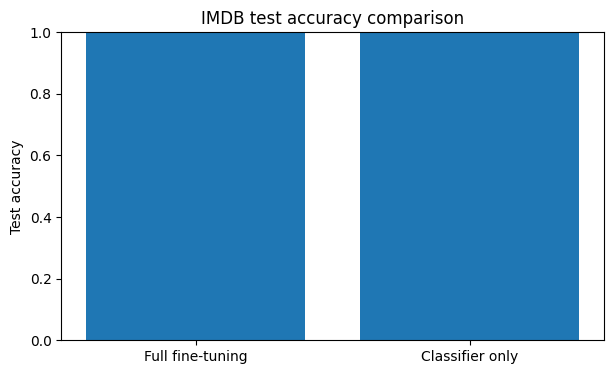

In [40]:
full_test_loss, full_test_acc = run_epoch(full_model, imdb_test_loader)
head_test_loss, head_test_acc = run_epoch(head_only_model, imdb_test_loader)

print(f"Full fine-tuning  | test loss: {full_test_loss:.4f} | test accuracy: {full_test_acc:.4f}")
print(f"Classifier only   | test loss: {head_test_loss:.4f} | test accuracy: {head_test_acc:.4f}")

results = {
    "Full fine-tuning": full_test_acc,
    "Classifier only": head_test_acc
}
plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values())
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("IMDB test accuracy comparison")
plt.show()

## 15. Classification report

In [41]:
def collect_predictions(model, loader):
    model.eval()
    predictions, labels_all = [], []
    with torch.no_grad():
        for input_ids, labels in loader:
            logits = model(input_ids.to(DEVICE))
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            labels_all.extend(labels.tolist())
    return labels_all, predictions

y_true, full_predictions = collect_predictions(full_model, imdb_test_loader)
_, head_predictions = collect_predictions(head_only_model, imdb_test_loader)

print("FULL FINE-TUNING")
print(classification_report(
    y_true, full_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

print("CLASSIFIER-ONLY")
print(classification_report(
    y_true, head_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

FULL FINE-TUNING
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00      5000
    Positive       0.00      0.00      0.00         0

    accuracy                           1.00      5000
   macro avg       0.50      0.50      0.50      5000
weighted avg       1.00      1.00      1.00      5000

CLASSIFIER-ONLY
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00      5000
    Positive       0.00      0.00      0.00         0

    accuracy                           1.00      5000
   macro avg       0.50      0.50      0.50      5000
weighted avg       1.00      1.00      1.00      5000



## 16. Predict sentiment for your own review

The prediction function uses the same tokenizer and vocabulary as training. The output is a probability distribution over Negative and Positive.


In [42]:
def predict_sentiment(text, model=full_model):
    model.eval()
    ids = encode_text(text)
    input_tensor = torch.tensor(ids, dtype=torch.long).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_id = int(probabilities.argmax().item())
    label = "Positive" if predicted_id == 1 else "Negative"

    return {
        "label": label,
        "negative_probability": float(probabilities[0].item()),
        "positive_probability": float(probabilities[1].item())
    }

print(predict_sentiment("This movie was wonderful. The acting and story were excellent!"))
print(predict_sentiment("A boring and disappointing film. I did not enjoy it."))

{'label': 'Negative', 'negative_probability': 0.9987926483154297, 'positive_probability': 0.0012073070975020528}
{'label': 'Negative', 'negative_probability': 0.9995321035385132, 'positive_probability': 0.00046785801532678306}


## 17. Save both fine-tuned models


In [43]:
torch.save(full_model.state_dict(), "imdb_full_fine_tuning.pt")
torch.save(head_only_model.state_dict(), "imdb_classifier_only.pt")
print("Saved both IMDB model weights.")

Saved both IMDB model weights.


## 18. What should you learn from this experiment?

| Feature | Full fine-tuning | Classifier-only |
|---|---|---|
| Embeddings | Updated | Frozen |
| Transformer encoder | Updated | Frozen |
| New classifier | Updated | Updated |
| Trainable parameter count | Larger | Much smaller |
| Compute/memory | Usually higher | Usually lower |
| Ability to adapt representations | Higher | Limited |

### Important interpretation
- Full fine-tuning often performs better when the source and target tasks differ, because the encoder can adapt to the target task.
- Classifier-only training is cheaper and can be useful when compute is limited or the source representations are already suitable.
- **Do not expect exactly 90% accuracy.** Results depend on sample limits, vocabulary, model size, epochs, random seed, and hardware. This compact model is an educational experiment, not a reproduction of a particular video's exact setup.
- Because the vocabulary is learned from AG News, many movie-review-specific words may become `<unk>`. A larger shared tokenizer or a pretrained tokenizer/Transformer can improve the experiment substantially.

### Suggested next experiments
1. Increase `AG_TRAIN_LIMIT` and `IMDB_TRAIN_LIMIT`.
2. Train for more epochs and compare validation curves.
3. Try `MAX_LEN = 256`.
4. Compare this custom model with a pretrained DistilBERT model.
5. Try a pretrained GloVe embedding matrix, then compare frozen and trainable embeddings.
